# Fig. 4h: malignant cells in a PanIN-like and a PDAC region of MH097_480

1. **Fig. 4h niches:** tumour niches of MH097_480 from the Stage 2 combined object (same plot as `stage2_niches.ipynb`).
2. **Fig. 4h malignant cells:** the malignant cells of MH097_480 in the same window, with the two regions marked.
3. **Regions:** malignant cells from a PanIN-like region and a PDAC region, compared by Hypoxia, IFNG and IL6 pathway scores, following the original PanIN notebook, from the final Stage 1 object.

DE, the other pathway scores, Leiden clustering and the plots that weren't saved are left out. PCA and UMAP are kept for the saved UMAP figure.

## Parameters

In [ ]:
# Folders and input files: set these before running (papermill parameters)
# Final Stage 1 objects, one subfolder per sample (<sample>/<sample>.h5ad)
STAGE1_DIR = "/path/to/stage1_output"
# The combined object written by stage2_niches.ipynb
STAGE2_COMBINED = "/path/to/stage2_output/Combined_CLR_transform_global_CN_stage2.h5ad"
OUTPUT_DIR = "/path/to/stage3_output/MH097_PanIN"
# The original subset object, not deposited, used only for the check at the end; set to None to skip it
ARCHIVED_FILE = "/path/to/original_subsets/MH097_malignant_SUBSET_PanIN_DE_rerun.h5ad"

In [20]:
import os

FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")

SAMPLE = "MH097_480"
# Regions as (x_min, x_max, y_min, y_max) in µm, from the original notebook
regions = {
    "PanIN": (2200, 5000, 1000, 4000),  # PanIN by pathology, but malignant by expression
    "PDAC": (8200, 9500, 3500, 4500),   # malignant cells surrounded by SPP1+ TAMs, OLR1+ TAMs and myofibroblasts
}
# Fig. 4h window
XLIM = (2000, 11000)
YLIM = (6200, 0)  # y-axis is inverted, so the first value is the bottom

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
import scanpy as sc
import squidpy as sq
import anndata as ad

os.makedirs(FIGURE_DIR, exist_ok=True)
sc.settings.figdir = FIGURE_DIR

## Fig. 4h: tumour niches and malignant cells

In [22]:
combined = sc.read_h5ad(STAGE2_COMBINED, backed="r")
in_sample = (combined.obs["sample"] == SAMPLE).values
df_plot = combined.obs.loc[in_sample, ["global_niche_CLR", "cell_class_threshold"]].copy()
df_plot[["x", "y"]] = np.asarray(combined.obsm["spatial"])[in_sample]
combined.file.close()
print(SAMPLE, len(df_plot), "cells")

MH097_480 194614 cells


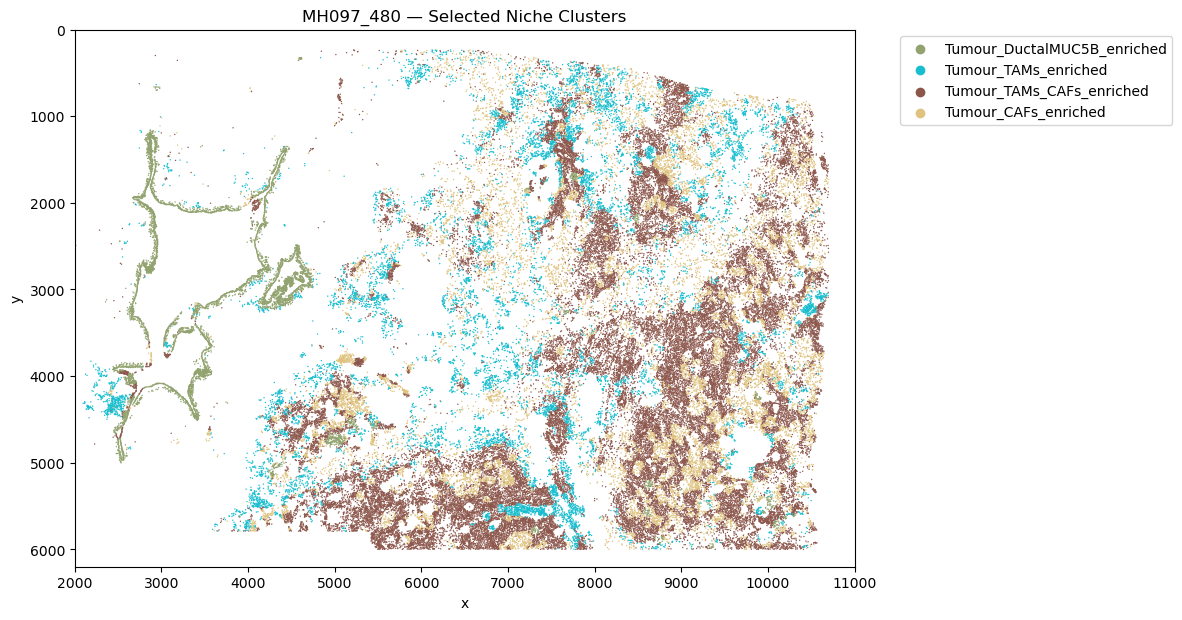

In [23]:
col_pal = {"Tumour_CAFs_enriched": "#DFC27D",
           "Tumour_TAMs_enriched": "#17becf",
           "Tumour_DuctalMUC5B_enriched": "#92A36F",
           "Tumour_TAMs_CAFs_enriched": "#8c564b"}


def window(title, file_name):
    ax = plt.gca()
    ax.set_aspect("equal")
    ax.invert_yaxis()
    plt.xlim(*XLIM)
    plt.ylim(*YLIM)
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURE_DIR, file_name), dpi=300, bbox_inches="tight")
    plt.show()


niche_cells = df_plot[df_plot["global_niche_CLR"].isin(col_pal)].copy()
niche_cells["global_niche_CLR"] = niche_cells["global_niche_CLR"].astype(str)
plt.figure(figsize=(12, 12))
sns.scatterplot(data=niche_cells, x="x", y="y", hue="global_niche_CLR", palette=col_pal,
                s=1, rasterized=True, linewidth=0)
window(f"{SAMPLE} — Selected Niche Clusters", "Fig4h_Representative_niches_97_480_zoom.pdf")

34013 malignant cells


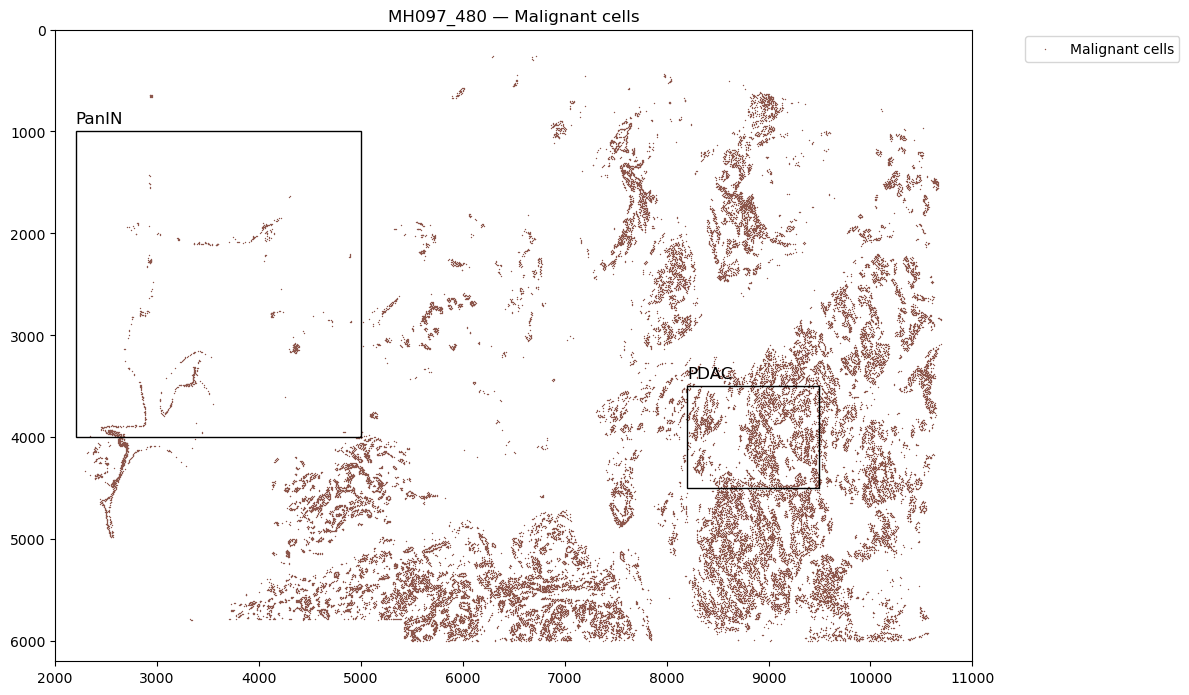

In [24]:
# The same window with only malignant cells, and the two regions used below
malignant_cells = df_plot[df_plot["cell_class_threshold"] == "Malignant cells"]
print(len(malignant_cells), "malignant cells")
plt.figure(figsize=(12, 12))
plt.scatter(malignant_cells["x"], malignant_cells["y"], s=1, c="#8c564b", linewidths=0, rasterized=True,
            label="Malignant cells")
for region, (x_min, x_max, y_min, y_max) in regions.items():
    plt.gca().add_patch(patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, fill=False, edgecolor="black", linewidth=1))
    plt.text(x_min, y_min - 80, region, fontsize=12)
window(f"{SAMPLE} — Malignant cells", "Fig4h_Malignant_cells_97_480_zoom.pdf")

## Malignant cells in the two regions

In [25]:
adata = sc.read_h5ad(os.path.join(STAGE1_DIR, SAMPLE, f"{SAMPLE}.h5ad"))


def region_cells(box):
    x_min, x_max, y_min, y_max = box
    return (
        (adata.obs['x_centroid'] >= x_min) & (adata.obs['x_centroid'] <= x_max) &
        (adata.obs['y_centroid'] >= y_min) & (adata.obs['y_centroid'] <= y_max)
    )


parts = []
for region, box in regions.items():
    part = adata[region_cells(box) & (adata.obs['cell_class_threshold'] == "Malignant cells")].copy()
    part.X = part.layers['counts'].copy()  # raw counts, re-normalised below
    part.obs["Region"] = region
    parts.append(part)
merged = ad.concat(parts, merge="same")
print(merged.obs['anno'].value_counts().to_string())

# As in the original: drop cells whose anno is another cell type (Malignant cells and Ductal_MUC6_REG1A are kept).
# Mixed_vSMCs_CAFs and CAFs_CXCL14 are added because three cells that were vSMCs or CAFs_MYO in the original object
# have these names in the final Stage 1 object
merged = merged[~merged.obs['anno'].isin(['CAFs_MYO', 'Ductal', 'Endothelial',
       'Neutrophils', 'Plasma', 'TAMs_OLR1', 'TAMs_SPP1',
       'vSMCs', 'Mixed_vSMCs_CAFs', 'CAFs_CXCL14'])].copy()
print(merged.obs["Region"].value_counts().to_string())

anno
Malignant cells      2837
Ductal_MUC6_REG1A     635
CAFs_MYO              143
Neutrophils            32
Ductal                 21
TAMs_SPP1               4
Mixed_vSMCs_CAFs        2
TAMs_OLR1               2
CAFs_CXCL14             1
Endothelial             1
Plasma                  1
Region
PDAC     2814
PanIN     658


In [26]:
sc.pp.calculate_qc_metrics(merged, percent_top=(10, 20, 50, 150), inplace=True)
cprobes = merged.obs["control_probe_counts"].sum() / merged.obs["total_counts"].sum() * 100
cwords = merged.obs["control_codeword_counts"].sum() / merged.obs["total_counts"].sum() * 100
print(f"Negative DNA probe count % : {cprobes}")
print(f"Negative decoding count % : {cwords}")

merged.layers["counts"] = merged.X.copy()
sc.pp.normalize_total(merged, inplace=True)
sc.pp.log1p(merged)
merged.layers['scaled'] = sc.pp.scale(merged, copy=True).X

sc.pp.pca(merged, n_comps=50, random_state=36)
sc.pp.neighbors(merged, n_neighbors=30, random_state=36)
sc.tl.umap(merged, random_state=36)

Negative DNA probe count % : 0.002365816786416426
Negative decoding count % : 0.004909069831814085


## Pathway scores

In [28]:
# Each set is scored separately, so leaving out the other sets doesn't change these scores
pathway_gene_sets = {
    "IFNG" : ["CMPK2","DDX60","GBP4","ICAM1","IDO1","IFIT1","IFIT2","IFIT3","ISG15","OASL","RSAD2","ZBP1"],
    "IL6":["IL6","IL6R","IL6ST","STAT3","TNFRSF1A","TNFRSF21","JUN","SOCS3"],#doi: 10.1042/CS20191211
    "HYPOXIA":["VEGFA","LDHA","SLC2A1","ARNT","ERO1A","HIF1A","CA9"], #doi: 10.3390/molecules27165192
}

pathway_scores = []
for pathway, genes in pathway_gene_sets.items():
    sc.tl.score_genes(merged, gene_list=genes, ctrl_size=20, random_state=22, score_name=f"{pathway}_pathway_score")
    pathway_scores.append(f"{pathway}_pathway_score")

# z-score across all cells in both regions
for key in pathway_scores:
    vals = merged.obs[key]
    merged.obs[key + "_z"] = (vals - vals.mean()) / vals.std()

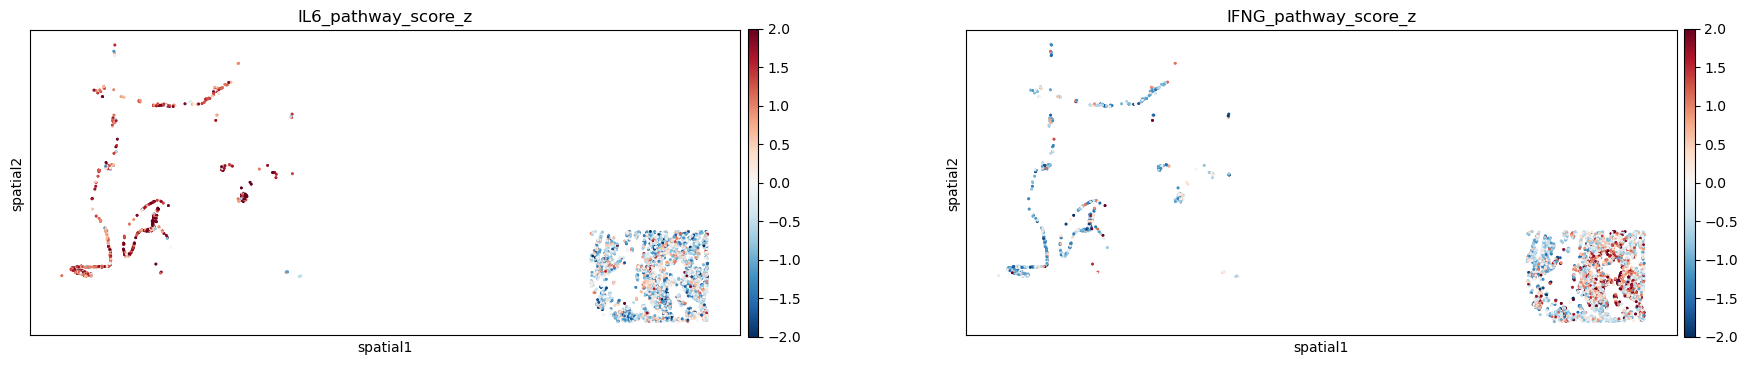

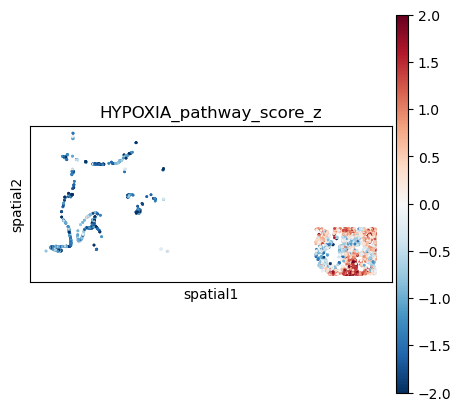

In [29]:
sq.pl.spatial_scatter(merged, library_id="spatial", shape=None, color=['IL6_pathway_score_z', 'IFNG_pathway_score_z'],
                      wspace=0.2, size=4, cmap='RdBu_r', vmin=-2, vmax=2, figsize=(9, 4), save='MH097_PanIN_signalling.pdf')
sq.pl.spatial_scatter(merged, library_id="spatial", shape=None, color=['HYPOXIA_pathway_score_z'],
                      size=4, cmap='RdBu_r', vmin=-2, vmax=2, figsize=(4.5, 4), save='MH097_PanIN_signalling_2.pdf')

In [30]:
merged.write_h5ad(os.path.join(OUTPUT_DIR, "MH097_malignant_PanIN_regions.h5ad"))

## Comparison with the original subset object

In [31]:
check = []
if ARCHIVED_FILE and os.path.exists(ARCHIVED_FILE):
    reference = sc.read_h5ad(ARCHIVED_FILE)
    shared = merged.obs_names.intersection(reference.obs_names)
    check += [
        ("Cells", merged.n_obs),
        ("Cells in original", reference.n_obs),
        ("Shared cells", len(shared)),
        ("Same region", f"{(merged.obs.loc[shared, 'Region'].astype(str) == reference.obs.loc[shared, 'Region'].astype(str)).mean():.4%}"),
    ]
    for key in pathway_scores:
        if key in reference.obs:
            check.append((f"{key}, max difference", float((merged.obs.loc[shared, key] - reference.obs.loc[shared, key]).abs().max())))
    check = pd.DataFrame(check, columns=["measure", "value"])
    check.to_csv(os.path.join(OUTPUT_DIR, "stage3_PanIN_check.tsv"), sep="\t", index=False)
    display(check)
else:
    print("No original subset object")

,measure,value
0,Cells,3472
1,Cells in original,3472
2,Shared cells,3472
3,Same region,100.0000%
4,"IFNG_pathway_score, max difference",0.0
5,"IL6_pathway_score, max difference",0.0
6,"HYPOXIA_pathway_score, max difference",0.0
